# Multi-Class Classification

Importing libraries

In [24]:
# ==========================================
#  IMPORTING REQUIRED LIBRARIES
# ==========================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display visualisations inside Jupyter Notebook
%matplotlib inline

# Set visualisation style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


Loading the dataset

In [25]:
# ==========================================
#  LOADING THE DATASET
# ==========================================

# Dataset URL
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

# Load dataset
df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


Understanding the dataset

In [26]:
# Display first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset dimensions

In [27]:
# Number of rows and columns
print("Dataset shape:", df.shape)

print("Total observations:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset shape: (150, 5)
Total observations: 150
Total columns: 5


Display dataset information

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


Statistical summary

In [29]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Examine the target variable

In [30]:
# Display unique flower species
print("Flower species:")
print(df["species"].unique())

# Count observations per species
print("\nSpecies distribution:")
print(df["species"].value_counts())

Flower species:
['setosa' 'versicolor' 'virginica']

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Data quality assessment

In [31]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [32]:
# Count duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1


Check data types

In [33]:
print(df.dtypes)

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object


Exploratory Data Analysis (EDA)

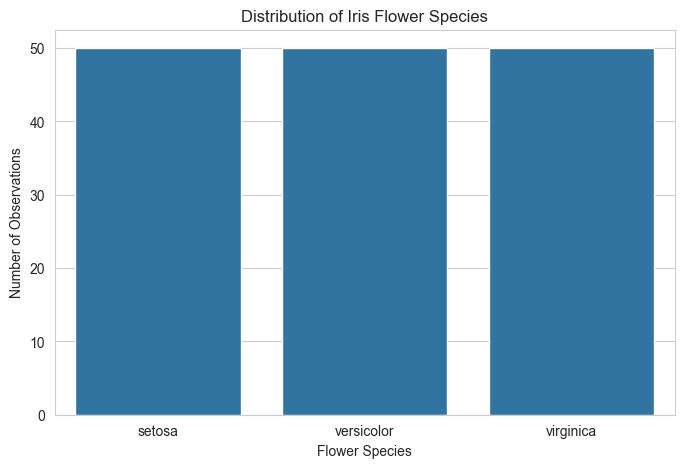

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Observations")

plt.show()

Feature distributions

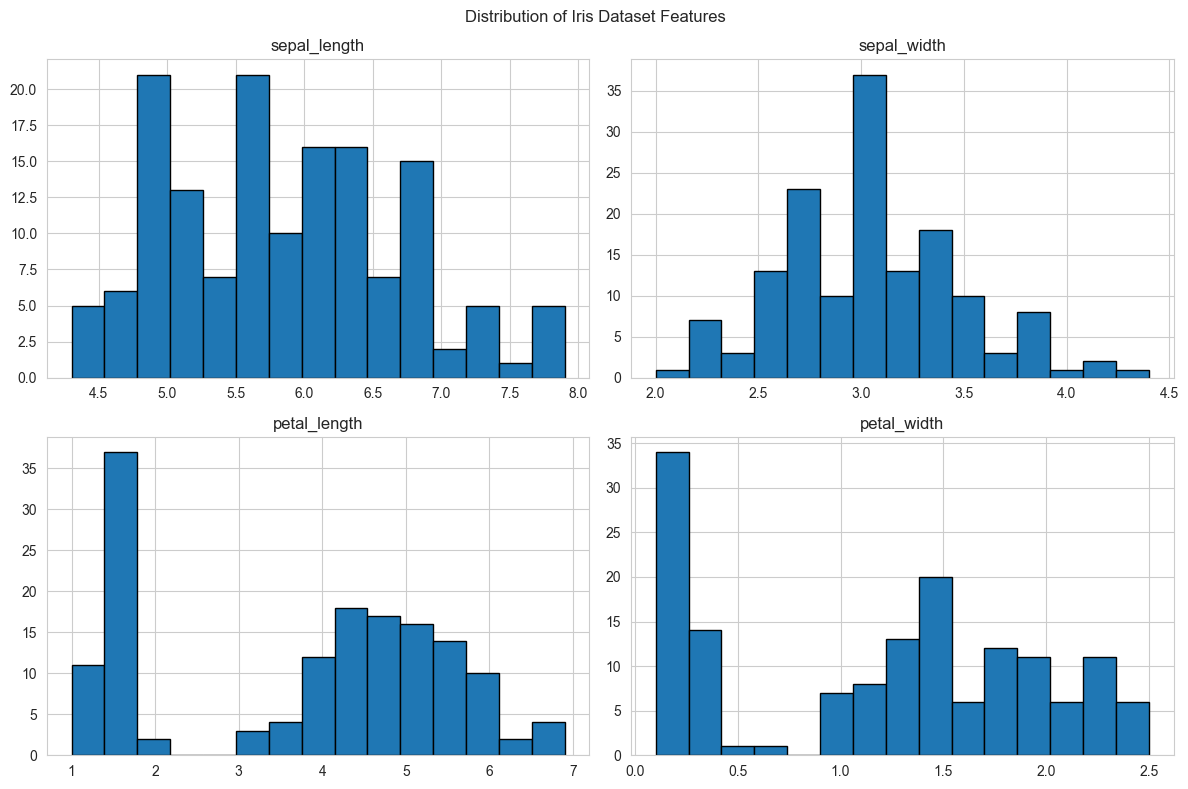

In [35]:
# Select numerical columns
numerical_features = df.select_dtypes(include=np.number)

# Plot histograms
numerical_features.hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Dataset Features")

plt.tight_layout()
plt.show()

Feature relationships using Pairplot

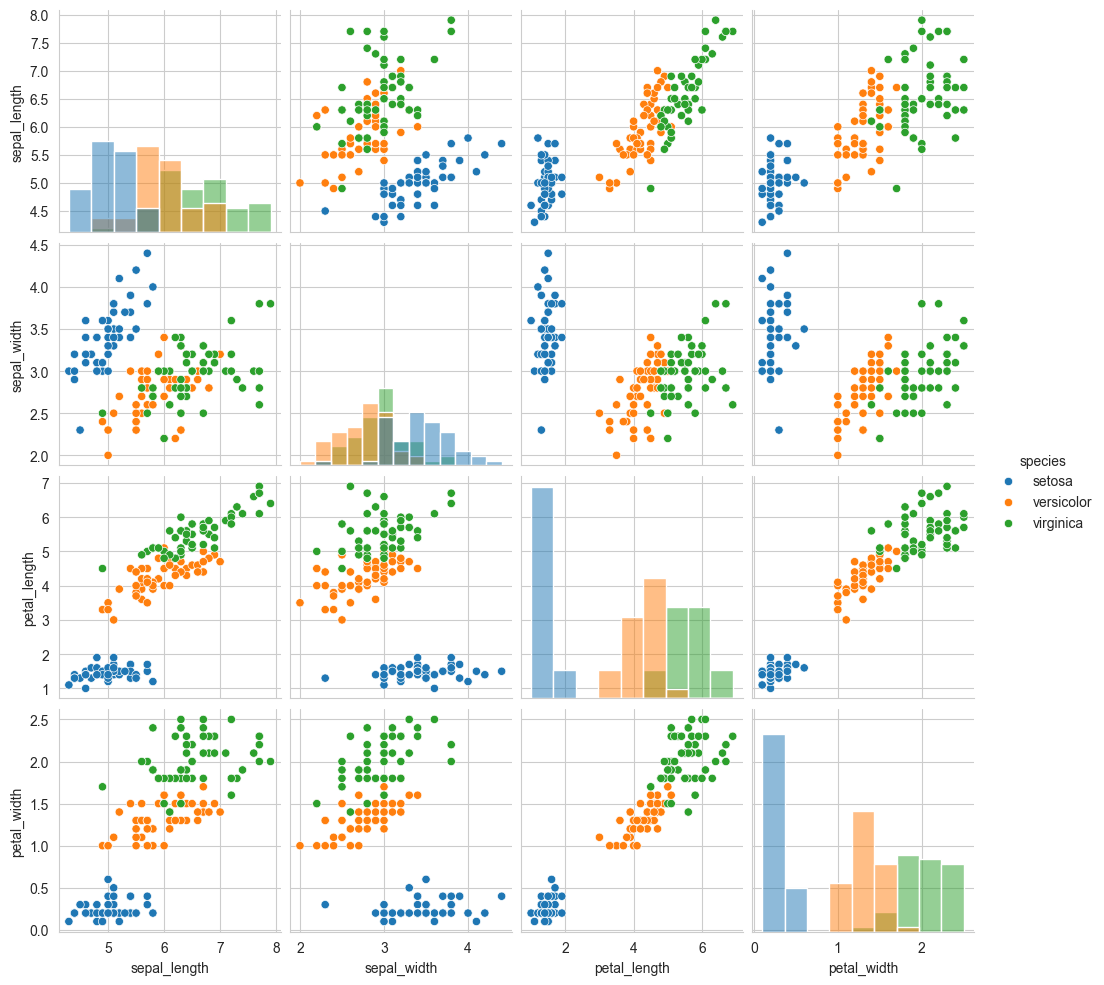

In [36]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

Correlation heatmap

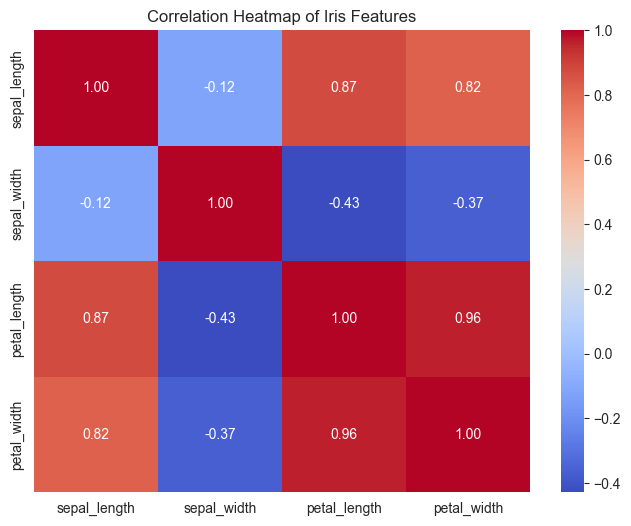

In [37]:
# Calculate correlations between numerical features
correlation = numerical_features.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Features")

plt.show()

Data preprocessing

Separate features and target

In [38]:
# Independent variables
X = df.drop(columns=["species"])

# Dependent variable
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


Split the dataset into training and testing sets

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


Feature scaling using StandardScaler

In [40]:
# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data: (120, 4)
Scaled testing data: (30, 4)


 MODEL DEVELOPMENT

 Logistic Regression

Logistic Regression is a supervised machine learning algorithm
used for classification problems. It predicts the probability
of an observation belonging to a particular class.

In [41]:
# ==========================================
#  LOGISTIC REGRESSION MODEL
# ==========================================

from sklearn.linear_model import LogisticRegression

# Initialise the Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [42]:
# Generate predictions using testing data
log_predictions = log_model.predict(X_test_scaled)

# Display actual and predicted values
results_log = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": log_predictions
})

display(results_log.head(10))

,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


 Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm
that makes predictions by learning a sequence of decision
rules based on input features.

In [43]:
# ==========================================
#  DECISION TREE MODEL
# ==========================================

from sklearn.tree import DecisionTreeClassifier

# Initialise Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [44]:
# Generate predictions
tree_predictions = tree_model.predict(X_test_scaled)

# Compare actual and predicted values
results_tree = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": tree_predictions
})

display(results_tree.head(10))

,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Evaluate Logistic Regression

In [45]:
# ==========================================
#  LOGISTIC REGRESSION EVALUATION
# ==========================================

log_accuracy = accuracy_score(y_test, log_predictions)

log_precision = precision_score(
    y_test, log_predictions, average="macro"
)

log_recall = recall_score(
    y_test, log_predictions, average="macro"
)

log_f1 = f1_score(
    y_test, log_predictions, average="macro"
)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")
print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1-score:", round(log_f1, 4))

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


Evaluate Decision Tree

In [46]:
# ==========================================
#  DECISION TREE EVALUATION
# ==========================================

tree_accuracy = accuracy_score(y_test, tree_predictions)

tree_precision = precision_score(
    y_test, tree_predictions, average="macro"
)

tree_recall = recall_score(
    y_test, tree_predictions, average="macro"
)

tree_f1 = f1_score(
    y_test, tree_predictions, average="macro"
)

print("DECISION TREE PERFORMANCE")
print("--------------------------")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1-score:", round(tree_f1, 4))

DECISION TREE PERFORMANCE
--------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


Generate classification reports

In [47]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        log_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [48]:
print("DECISION TREE CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        tree_predictions,
        zero_division=0
    )
)

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Confusion Matrix Visualisation

Logistic Regression confusion matrix

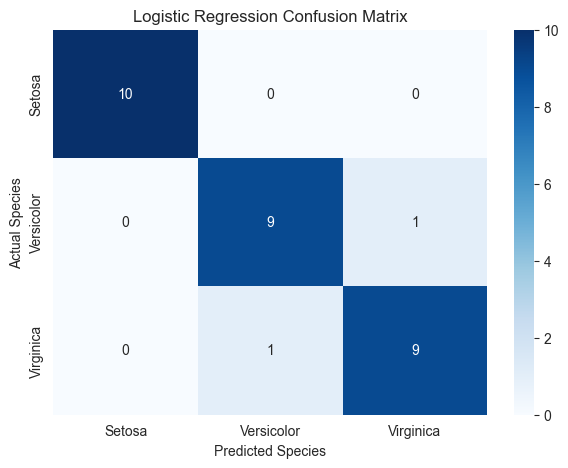

In [49]:
# ==========================================
#  LOGISTIC REGRESSION CONFUSION MATRIX
# ==========================================

# Calculate confusion matrix
log_cm = confusion_matrix(
    y_test,
    log_predictions,
    labels=["setosa", "versicolor", "virginica"]
)

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    log_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Setosa", "Versicolor", "Virginica"],
    yticklabels=["Setosa", "Versicolor", "Virginica"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

Decision Tree confusion matrix

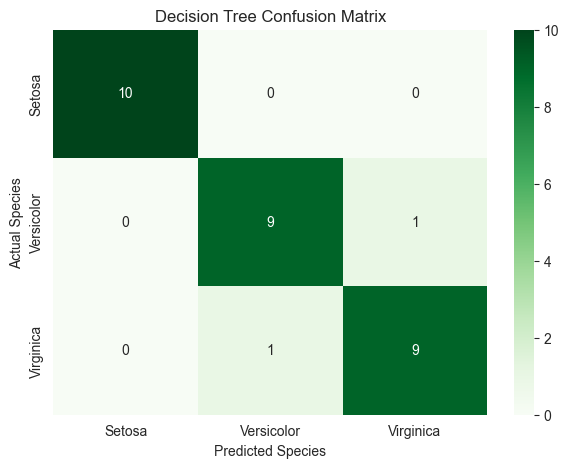

In [50]:
# ==========================================
#  DECISION TREE CONFUSION MATRIX
# ==========================================

tree_cm = confusion_matrix(
    y_test,
    tree_predictions,
    labels=["setosa", "versicolor", "virginica"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Setosa", "Versicolor", "Virginica"],
    yticklabels=["Setosa", "Versicolor", "Virginica"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

Model Benchmarking and Comparison

In [51]:
# ==========================================
#  MODEL PERFORMANCE COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],

    "Accuracy": [
        log_accuracy,
        tree_accuracy
    ],

    "Precision": [
        log_precision,
        tree_precision
    ],

    "Recall": [
        log_recall,
        tree_recall
    ],

    "F1-Score": [
        log_f1,
        tree_f1
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


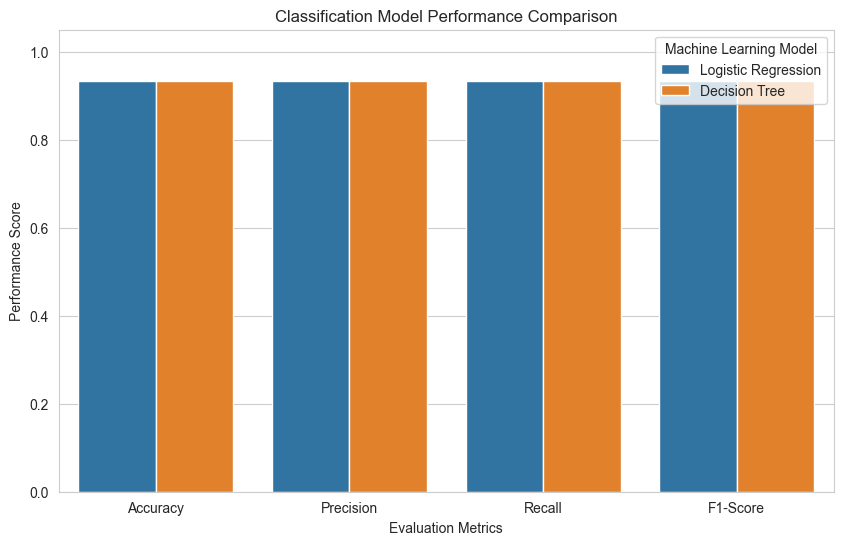

In [52]:
# ==========================================
#  MODEL PERFORMANCE VISUALISATION
# ==========================================

comparison_melted = comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.legend(title="Machine Learning Model")

plt.show()

Decision Boundary Visualisation

In [53]:
# ==========================================
#  PREPARING DATA FOR DECISION BOUNDARIES
# ==========================================

# Select two features
X_2d = df[["petal_length", "petal_width"]]

# Target variable
y_2d = df["species"]

# Split using the same random seed and stratification
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# Scale the two features
scaler_2d = StandardScaler()

X_2d_train_scaled = scaler_2d.fit_transform(X_2d_train)

X_2d_test_scaled = scaler_2d.transform(X_2d_test)

print("Two-feature dataset prepared successfully!")

Two-feature dataset prepared successfully!


In [54]:
# Logistic Regression using two features
log_2d = LogisticRegression(max_iter=1000, random_state=42)

log_2d.fit(X_2d_train_scaled, y_2d_train)

# Decision Tree using two features
tree_2d = DecisionTreeClassifier(random_state=42)

tree_2d.fit(X_2d_train_scaled, y_2d_train)

print("Two-feature visualisation models trained!")

Two-feature visualisation models trained!


Create a decision boundary plotting function

In [55]:
# ==========================================
#  DECISION BOUNDARY FUNCTION
# ==========================================

def plot_decision_boundary(model, X, y, title):

    # Convert data to NumPy arrays
    X = np.asarray(X)
    y = np.asarray(y)

    # Create a mesh grid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Generate predictions for every grid point
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    predictions = model.predict(grid_points)

    # Convert predictions into numerical labels
    class_mapping = {
        label: index
        for index, label in enumerate(model.classes_)
    }

    Z = np.array([
        class_mapping[label] for label in predictions
    ])

    Z = Z.reshape(xx.shape)

    # Plot decision regions
    plt.figure(figsize=(9, 6))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.3,
        cmap="viridis"
    )

    # Plot actual observations
    sns.scatterplot(
        x=X[:, 0],
        y=X[:, 1],
        hue=y,
        palette="viridis",
        edgecolor="black",
        s=60
    )

    plt.title(title)
    plt.xlabel("Standardised Petal Length")
    plt.ylabel("Standardised Petal Width")

    plt.legend(title="Actual Species")

    plt.show()

Logistic Regression decision boundary

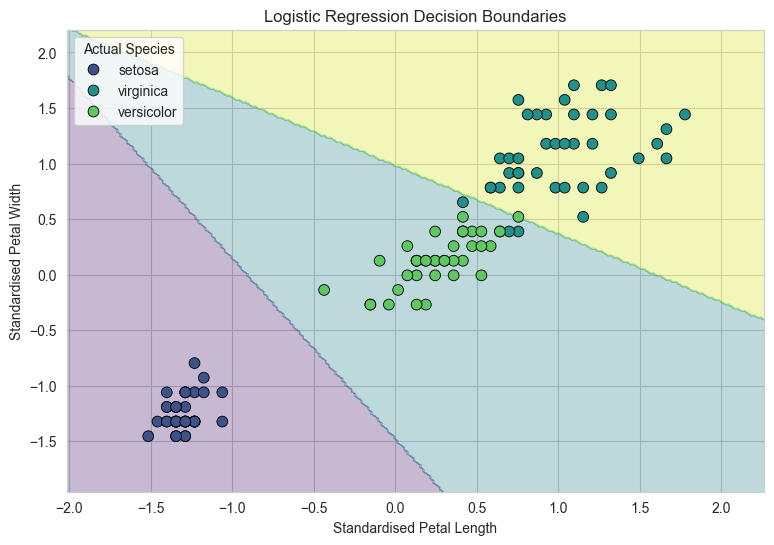

In [56]:
plot_decision_boundary(
    log_2d,
    X_2d_train_scaled,
    y_2d_train,
    "Logistic Regression Decision Boundaries"
)

Decision Tree decision boundary

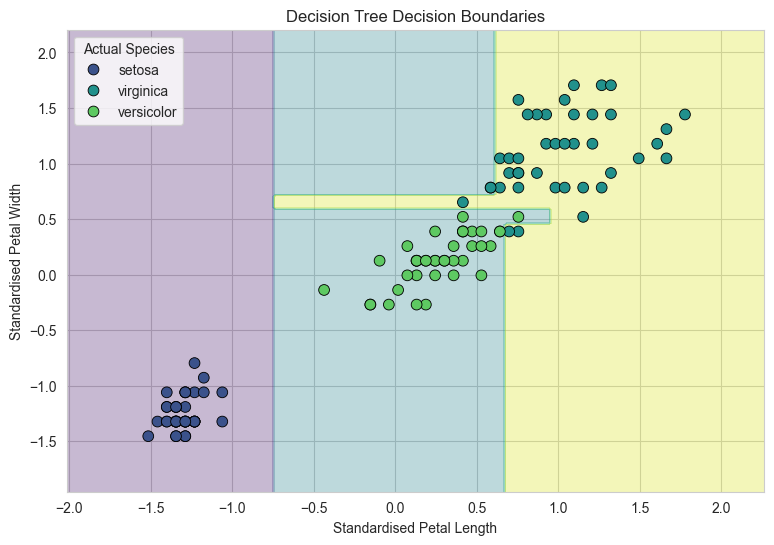

In [57]:
plot_decision_boundary(
    tree_2d,
    X_2d_train_scaled,
    y_2d_train,
    "Decision Tree Decision Boundaries"
)

Understanding the Decision Tree

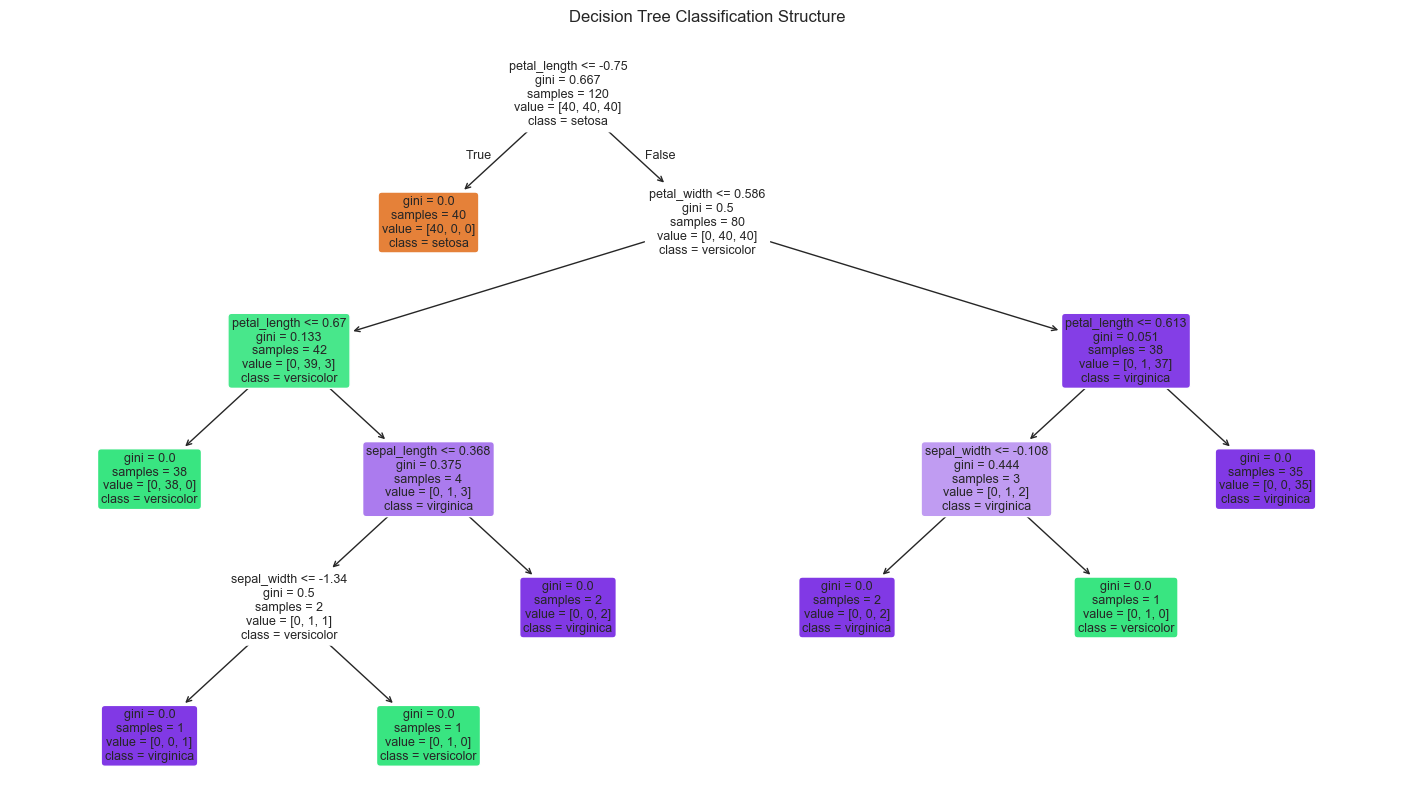

In [58]:
# ==========================================
#  DECISION TREE VISUALISATION
# ==========================================

from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classification Structure")

plt.show()

In [59]:
# ==========================================
#  FEATURE IMPORTANCE
# ==========================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
2,petal_length,0.558568
3,petal_width,0.406015
1,sepal_width,0.029167
0,sepal_length,0.006250


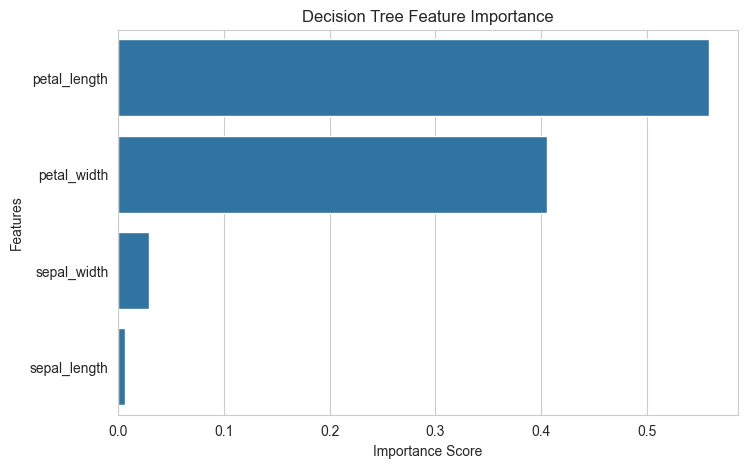

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [61]:
# ==========================================
#  FINAL MODEL SELECTION
# ==========================================

best_model = comparison.loc[
    comparison["Accuracy"].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-Score"], 4))

BEST PERFORMING MODEL
---------------------
Model: Logistic Regression
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


# CONCLUSION AND RECOMMENDATIONS

Project Summary

This project implemented two supervised machine learning classification algorithms, Logistic Regression and Decision Tree, using the Iris dataset.

The dataset was explored, cleaned and prepared before being divided into training and testing sets using an 80/20 split. Feature scaling was performed using StandardScaler.


Model Performance

The models were evaluated using accuracy, precision, recall and F1-score.

- Logistic Regression achieved an accuracy of 0.9333.
- Decision Tree achieved an accuracy of 0.9333.

Based on the evaluation results, both the models demonstrated same overall performance.


Key Findings

The confusion matrices helped identify correct predictions and classification errors across the three Iris species.

The decision boundary visualisations demonstrated how the two algorithms separate flower species based on petal measurements.

Feature importance analysis also provided insight into which measurements contributed most to the Decision Tree's classification decisions.


Recommendations and Further Work

- Experiment with additional classification algorithms such as Random Forest and Support Vector Machines.
- Apply hyperparameter tuning to improve model performance.
- Use cross-validation to obtain a more reliable estimate of model generalisation.
- Investigate the effect of different feature combinations on classification performance.


Final Conclusion

The project demonstrated the application of supervised machine learning for multi-class classification and highlighted the importance of data preprocessing, model training, evaluation and performance comparison.